# Analiza hate speech wokół wydarzenia – Youtube: Smierc_Zolnierza

Notebook analizuje **tylko komentarze z Youtube** dla jednego wydarzenia. Wczytuje wynik klasyfikacji
(`data/interim/youtube/<data>_<wydarzenie>/labeled/comments.csv` – regex + LLM) i łączy go z oczyszczonymi komentarzami
(`.../clean/comments.csv`), skąd bierze datę, `relative_day`, autora, wątek, lajki.

**Etykiety** (komentarz ma etykietę, jeśli wykrył ją LLM **albo** regex):

| etykieta | źródło |
|---|---|
| `hate` | `llm_is_hate_general` ∨ `hate_auto` ∨ `hate_migrant` (hate wobec migrantów jest też hate) |
| `hate_migrant` | `llm_is_hate_migrants` ∨ `hate_migrants_auto` |
| `migrant` | `llm_is_about_migration` |

**Okresy:** `przed` = `relative_day < 0`, `po` = `relative_day >= 0` (dzień wydarzenia liczony do „po”; zmień `POST_FROM_DAY`).

Aby przeanalizować inne wydarzenie, zmień tylko `EVENT` w komórce konfiguracyjnej.

In [1]:
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import confint_proportions_2indep, proportion_confint
from wordcloud import WordCloud

# katalog projektu = pierwszy katalog w górę, który zawiera events.json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())

# ---- konfiguracja ----
PLATFORM = "youtube"
EVENT = "Smierc_Zolnierza"  # np. Smierc_Zolnierza, Bojka_Srem, Strategia_Migracyjna, Dezinformacja_Krakow,
                        #     Ceuta_Masowe_Przekroczenie, Atak_Kamienna_Gora
POST_FROM_DAY = 0       # od którego relative_day liczymy okres "po"
MIN_DAILY_N = 10        # min. liczba komentarzy w dniu, by liczyć dzienny odsetek w testach
TOP_N_WORDS = 20
SEED = 42

LABELS = ["hate", "hate_migrant", "migrant"]
LABEL_NAMES = {"hate": "hate (ogólny)", "hate_migrant": "hate wobec migrantów", "migrant": "o migracji"}

# kolory: kategoryczne sloty w stałej kolejności + neutralne tusze
COLORS = {"komentarze": "#2a78d6", "hate": "#eb6834", "hate_migrant": "#1baf7a", "migrant": "#eda100",
          "przed": "#8a8984", "po": "#2a78d6"}
BAR_BG = "#b7d3f6"
INK, INK2 = "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.figsize": (13, 4.5), "figure.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.max_colwidth", 200)


def fmt_p(t, digits=3):
    # kolumny z p-value jako tekst w notacji naukowej (round() zamieniłby małe p na 0)
    t = t.copy()
    for c in t.columns:
        if c == "p" or c.startswith("p "):
            t[c] = t[c].map(lambda v: f"{v:.3g}")
    return t.round(digits)

## 0. Wczytanie danych

In [2]:
META_COLS = [
    "comment_id",
    "platform",
    "relative_day",
    "created_date",
    "created_at",
    "thread_id",
    "post_id",
    "depth",
    "author_id",
    "likes",
    "ukraine_related",
    "refugee_migrant_related",
    "political",
]
EVENTS = json.loads((ROOT / "events.json").read_text(encoding="utf-8"))


def to_bool(s):
  return (
      s.fillna(False)
      .astype(str)
      .str.strip()
      .str.lower()
      .isin(["true", "1", "1.0"])
  )


def load_event(event, platform=PLATFORM, post_from_day=POST_FROM_DAY):
  event_date = pd.Timestamp(EVENTS[event])
  event_dir = (
      ROOT / "data" / "interim" / platform / f"{event_date:%Y-%m-%d}_{event}"
  )

  labeled_file = event_dir / "labeled" / "comments.csv"
  filtered_file = event_dir / "filtered" / "comments.csv"

  # Wczytanie etykietowanych komentarzy o migrantach
  labeled = pd.read_csv(labeled_file, dtype={"comment_id": str})

  # Wczytanie wszystkich komentarzy
  all_comments = pd.read_csv(
      filtered_file,
      encoding="utf-8-sig",
      dtype={"comment_id": str},
      usecols=lambda c: c in META_COLS or c in ["text", "comment_id"],
  ).drop_duplicates("comment_id")

  # Złączenie typu LEFT - bazą są wszystkie komentarze z filtered/comments.csv
  df = all_comments.merge(
      labeled, on="comment_id", how="left", suffixes=("", "_labeled")
  )

  df["created_date"] = pd.to_datetime(df["created_date"])

  # Komentarze obecne w labeled/comments.csv to te dotyczące migrantów
  labeled_ids = set(labeled["comment_id"].dropna())
  df["migrant"] = df["comment_id"].isin(labeled_ids)

  # Przypisanie etykiet hate (dla komentarzy spoza labeled wartości wyniosą False)
  df["hate_migrant"] = to_bool(df["llm_is_hate_migrants"]) | to_bool(
      df.get("human_hate_migrants", pd.Series(False, index=df.index))
  )
  df["hate"] = (
      to_bool(df["llm_is_hate"])
      | to_bool(df.get("human_hate", pd.Series(False, index=df.index)))
      | df["hate_migrant"]
  )

  df["okres"] = np.where(df["relative_day"] >= post_from_day, "po", "przed")
  df["po"] = (df["okres"] == "po").astype(int)
  df["text"] = df["text"].fillna("").astype(str)

  return df, event_date, event_dir, len(labeled)


df, EVENT_DATE, EVENT_DIR, n_res = load_event(EVENT)

print(
    f"platforma: {PLATFORM}  |  wydarzenie: {EVENT}  |  dzień 0 ="
    f" {EVENT_DATE:%Y-%m-%d}"
)
print("katalog:", EVENT_DIR.relative_to(ROOT))
print(
    f"wiersze w labeled/comments.csv: {n_res}, ogółem po złączeniu z filtered:"
    f" {len(df)}"
)
print(
    f"komentarze o migrantach (migrant=True): {df['migrant'].sum()}"
    f" ({df['migrant'].mean():.2%})"
)
print(
    f"zakres relative_day: {df['relative_day'].min()} .."
    f" {df['relative_day'].max()}"
)

platforma: youtube  |  wydarzenie: Smierc_Zolnierza  |  dzień 0 = 2024-06-06
katalog: data\interim\youtube\2024-06-06_Smierc_Zolnierza
wiersze w labeled/comments.csv: 4801, ogółem po złączeniu z filtered: 37832
komentarze o migrantach (migrant=True): 4801 (12.69%)
zakres relative_day: -5 .. 18


## 1. Liczba komentarzy i odsetek hate / hate_migrant / migrant – przed, po i ogółem

In [3]:
def summarize(g):
    out = {"komentarze": len(g), "dni": g["relative_day"].nunique(),
           "komentarzy / dzień": len(g) / max(g["relative_day"].nunique(), 1)}
    for lab in LABELS:
        out[f"{lab} [n]"] = int(g[lab].sum())
    for lab in LABELS:
        out[f"{lab} [%]"] = 100 * g[lab].mean()
    # jaki odsetek komentarzy o migracji jest hejtem wobec migrantów
    out["hate_migrant wśród migrant [%]"] = 100 * g.loc[g["migrant"], "hate_migrant"].mean()
    return pd.Series(out)


summary = pd.DataFrame({
    "przed": summarize(df[df["okres"] == "przed"]),
    "po": summarize(df[df["okres"] == "po"]),
    "ogółem": summarize(df),
}).T
display(summary.round(2))

,komentarze,dni,komentarzy / dzień,hate [n],hate_migrant [n],migrant [n],hate [%],hate_migrant [%],migrant [%],hate_migrant wśród migrant [%]
przed,99.0,2.0,49.50,1.0,1.0,3.0,1.01,1.01,3.03,33.33
po,37733.0,15.0,2515.53,2843.0,2111.0,4798.0,7.53,5.59,12.72,44.00
ogółem,37832.0,17.0,2225.41,2844.0,2112.0,4801.0,7.52,5.58,12.69,43.99


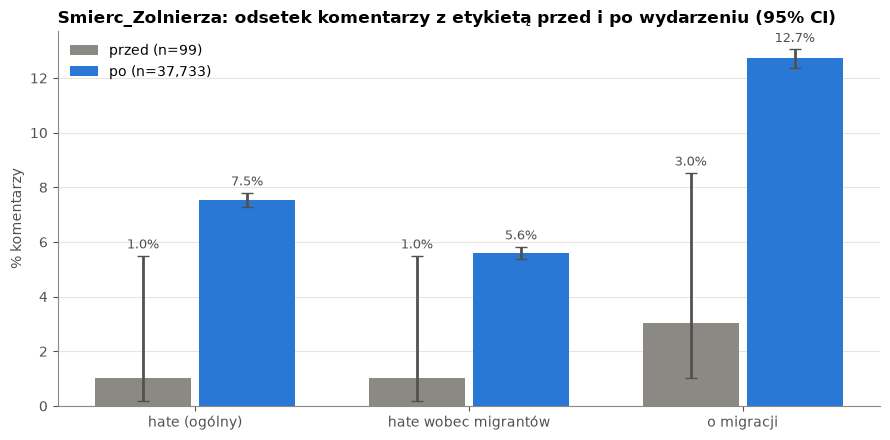

In [4]:
# odsetki z 95% CI (Wilson) - przed vs po
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(LABELS))
w = 0.38
for i, okres in enumerate(["przed", "po"]):
    g = df[df["okres"] == okres]
    k = np.array([g[lab].sum() for lab in LABELS])
    n = len(g)
    lo, hi = proportion_confint(k, n, method="wilson")
    p = k / n
    bars = ax.bar(x + (i - 0.5) * w, 100 * p, w - 0.03, color=COLORS[okres], label=f"{okres} (n={n:,})",
                  yerr=[100 * (p - lo), 100 * (hi - p)], capsize=4, ecolor=INK2)
    ax.bar_label(bars, labels=[f"{v:.1f}%" for v in 100 * p], padding=3, color=INK2, fontsize=9)
ax.set_xticks(x, [LABEL_NAMES[l] for l in LABELS])
ax.set_ylabel("% komentarzy")
ax.set_title(f"{EVENT}: odsetek komentarzy z etykietą przed i po wydarzeniu (95% CI)")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Liczba komentarzy per dzień

Na wszystkich wykresach dziennych: linia przerywana = dzień 0, kropkowana = dzień z max liczbą komentarzy, kreska-kropka = dzień z min liczbą komentarzy.

max: dzień 14 (2024-06-20), 7132 komentarzy
min: dzień -3 (2024-06-03), 0 komentarzy


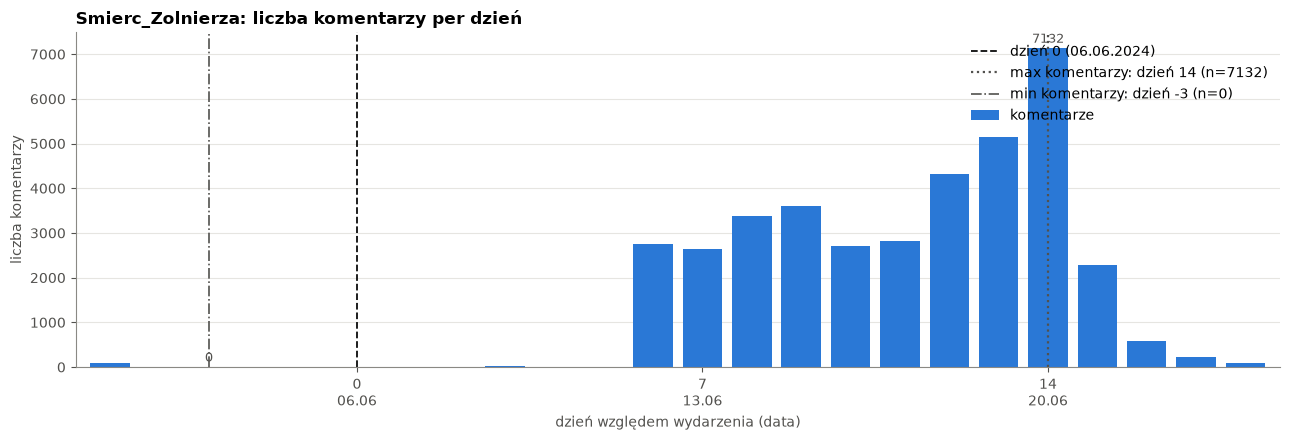

In [5]:
days = pd.RangeIndex(df["relative_day"].min(), df["relative_day"].max() + 1, name="relative_day")
daily = (df.groupby("relative_day")
           .agg(komentarze=("comment_id", "size"), hate=("hate", "sum"),
                hate_migrant=("hate_migrant", "sum"), migrant=("migrant", "sum"))
           .reindex(days, fill_value=0))
daily["data"] = EVENT_DATE + pd.to_timedelta(daily.index, unit="D")
for lab in LABELS:
    daily[f"{lab}_%"] = 100 * daily[lab] / daily["komentarze"].replace(0, np.nan)

DAY_MAX = int(daily["komentarze"].idxmax())
DAY_MIN = int(daily["komentarze"].idxmin())
print(f"max: dzień {DAY_MAX} ({daily.loc[DAY_MAX, 'data']:%Y-%m-%d}), {daily.loc[DAY_MAX, 'komentarze']} komentarzy")
print(f"min: dzień {DAY_MIN} ({daily.loc[DAY_MIN, 'data']:%Y-%m-%d}), {daily.loc[DAY_MIN, 'komentarze']} komentarzy")


def format_days_axis(ax, step=7):
    ticks = [d for d in daily.index if d % step == 0]
    ax.set_xticks(ticks, [f"{d}\n{daily.loc[d, 'data']:%d.%m}" for d in ticks])
    ax.set_xlim(daily.index.min() - 0.7, daily.index.max() + 0.7)
    ax.set_xlabel("dzień względem wydarzenia (data)")


def mark_days(ax):
    n_max, n_min = daily.loc[DAY_MAX, "komentarze"], daily.loc[DAY_MIN, "komentarze"]
    ax.axvline(0, color=INK, ls="--", lw=1.3, label=f"dzień 0 ({EVENT_DATE:%d.%m.%Y})")
    ax.axvline(DAY_MAX, color=INK2, ls=":", lw=1.6, label=f"max komentarzy: dzień {DAY_MAX} (n={n_max})")
    ax.axvline(DAY_MIN, color=INK2, ls="-.", lw=1.2, label=f"min komentarzy: dzień {DAY_MIN} (n={n_min})")
    format_days_axis(ax)


fig, ax = plt.subplots()
ax.bar(daily.index, daily["komentarze"], width=0.8, color=COLORS["komentarze"], label="komentarze")
for d in (DAY_MAX, DAY_MIN):
    ax.annotate(f"{daily.loc[d, 'komentarze']}", (d, daily.loc[d, "komentarze"]), xytext=(0, 4),
                textcoords="offset points", ha="center", color=INK2, fontsize=9)
mark_days(ax)
ax.set_ylabel("liczba komentarzy")
ax.set_title(f"{EVENT}: liczba komentarzy per dzień")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 3. Hate i hate_migrant per dzień

3a – same etykiety, 3b – nałożone na liczbę wszystkich komentarzy (ta sama oś, te same jednostki), 3c – odsetek dzienny (normalizuje wolumen).

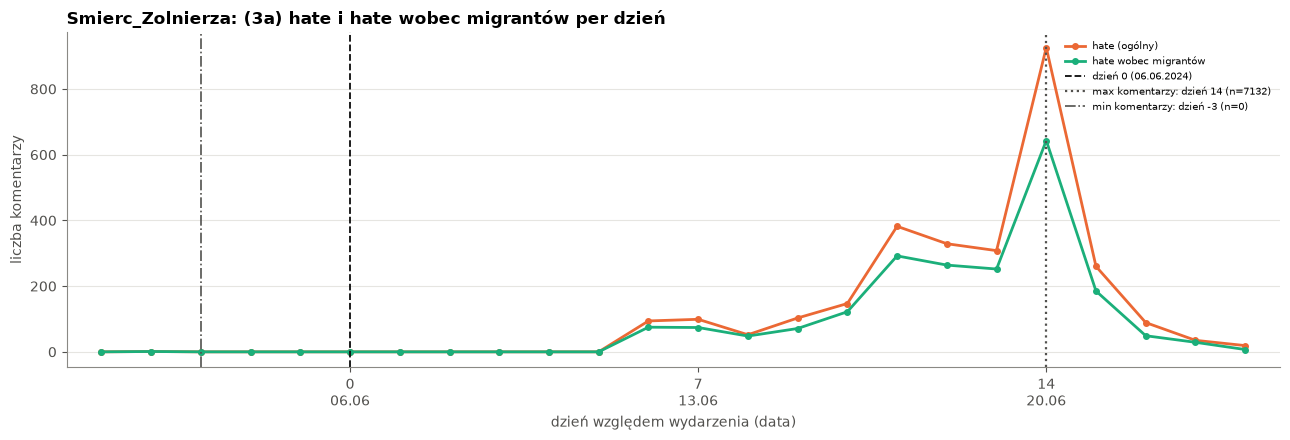

In [6]:
fig, ax = plt.subplots()
for lab in ["hate", "hate_migrant"]:
    ax.plot(daily.index, daily[lab], marker="o", ms=4, color=COLORS[lab], label=LABEL_NAMES[lab])
mark_days(ax)
ax.set_ylabel("liczba komentarzy")
ax.set_title(f"{EVENT}: (3a) hate i hate wobec migrantów per dzień")
ax.legend(loc="upper right", fontsize=7)
plt.tight_layout()
plt.show()

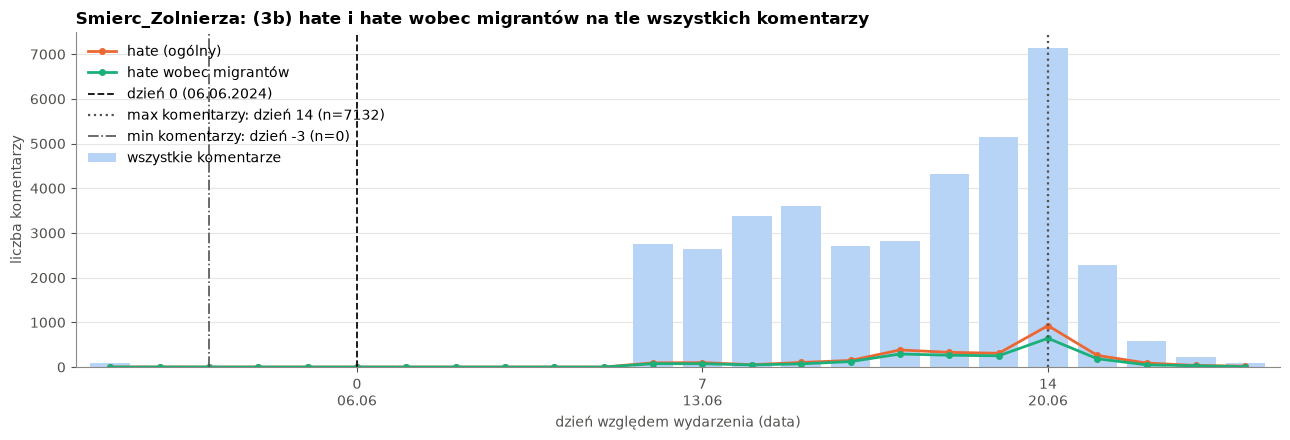

In [7]:
fig, ax = plt.subplots()
ax.bar(daily.index, daily["komentarze"], width=0.8, color=BAR_BG, label="wszystkie komentarze")
for lab in ["hate", "hate_migrant"]:
    ax.plot(daily.index, daily[lab], marker="o", ms=4, color=COLORS[lab], label=LABEL_NAMES[lab])
mark_days(ax)
ax.set_ylabel("liczba komentarzy")
ax.set_title(f"{EVENT}: (3b) hate i hate wobec migrantów na tle wszystkich komentarzy")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

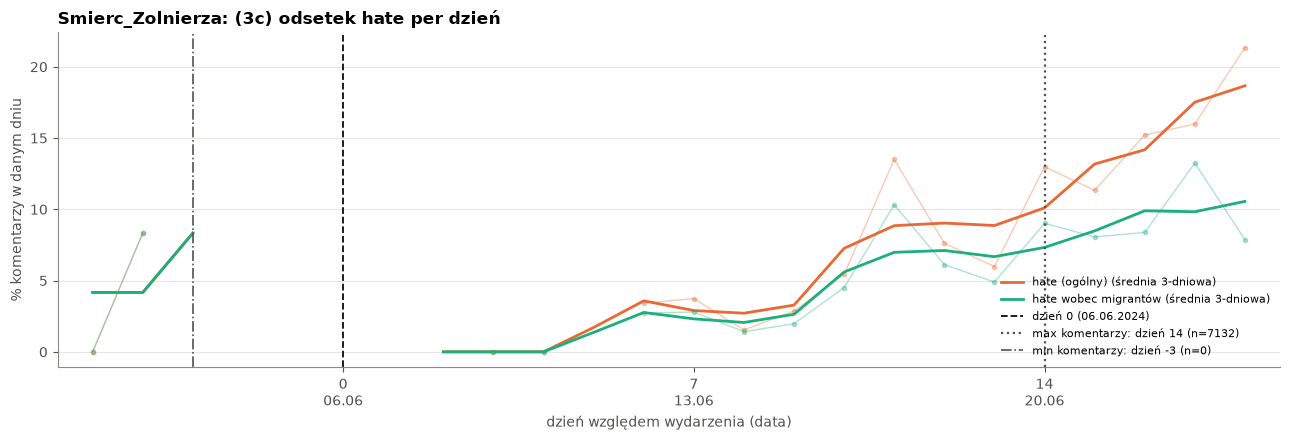

In [8]:
fig, ax = plt.subplots()
for lab in ["hate", "hate_migrant"]:
    ax.plot(daily.index, daily[f"{lab}_%"], marker="o", ms=3, lw=1, alpha=0.35, color=COLORS[lab])
    roll = daily[f"{lab}_%"].rolling(3, center=True, min_periods=1).mean()
    ax.plot(daily.index, roll, color=COLORS[lab], label=f"{LABEL_NAMES[lab]} (średnia 3-dniowa)")
mark_days(ax)
ax.set_ylabel("% komentarzy w danym dniu")
ax.set_title(f"{EVENT}: (3c) odsetek hate per dzień")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## 4. Top słowa w komentarzach `hate_migrant`

Tokenizacja: małe litery, bez linków/@wzmianek, słowa ≥ 3 litery, bez stop-słów. Brak lematyzacji – odmiany
(np. *ukraińcy* / *ukraińców*) liczą się osobno.

komentarze hate_migrant: 2112, unikalnych słów: 17283


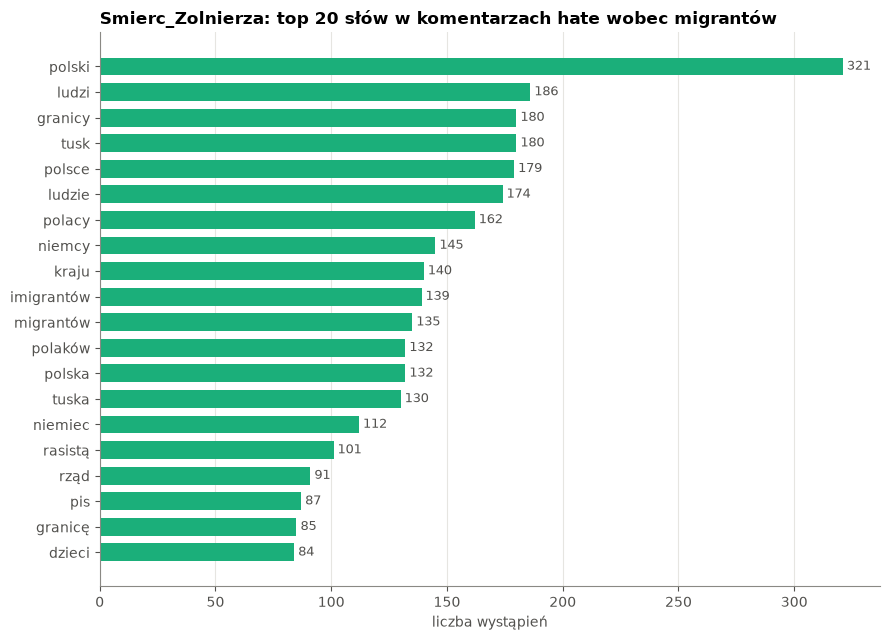

In [9]:
STOPWORDS_PL = set('''
a aby ach acz aczkolwiek aj albo ale ależ ani aż bardziej bardzo bez bo bowiem by byli bym bynajmniej być był była było były będzie będą
cali cała cały chce chcą ci cię ciebie co cokolwiek coraz coś czasami czasem czemu czy czyli często daleko dla dlaczego dlatego do dobrze
dokąd dość dużo dwa dwaj dwie dwoje dziś dzisiaj gdy gdyby gdyż gdzie gdziekolwiek gdzieś go i ich ile im inna inne inny innych iż ja ją
jak jakaś jakby jaki jakichś jakie jakiś jakiż jakkolwiek jako jakoś je jeden jedna jedno jednak jednakże jego jej jemu jest jestem jeszcze
jeśli jeżeli już ją każdy kiedy kilka kimś kto ktokolwiek ktoś która które którego której który których którym którzy ku lat lecz lub
ma mają mam mamy mało mi mimo między mną mnie mogą moi moim moja moje może możliwe można mój mu musi my na nad nam nami nas nasi nasz nasza
nasze naszego naszych natomiast natychmiast nawet nic nich nie niech niego niej niemu nigdy nim nimi niż no o obok od około on ona one oni
ono oraz oto owszem pan pana pani po pod podczas pomimo ponad ponieważ powinien powinna powinni powinno poza prawie przecież przed przede
przedtem przez przy roku również sam sama są się skąd sobie sobą sposób swoje ta tak taka taki takie także tam te tego tej temu ten teraz
też to tobą tobie toteż trzeba tu tutaj twoi twoim twoja twoje twym twój ty tych tylko tym u w wam wami was wasz wasza wasze we według
wiele wielu więc więcej wszyscy wszystkich wszystkie wszystkim wszystko wtedy wy właśnie z za zapewne zawsze ze zł znowu znów został żaden
żadna żadne żadnych że żeby tez juz sie jak ktory ktora ktore bylo byl beda bedzie moze takze zeby ze tylko wiec niz przez tego tym jeszcze
tych tej mnie mieć mają ma mial miał było będą bylo były jakis jakies cos nikt nikogo niczego wszystkiego swój swoją swojej swoich swoim
naszym tymi takich takiej takim tamtych coś ktoś kogoś czegoś bym byś byście byśmy będę będziesz będziemy jestes jesteś jesteśmy
http https www com html pdf amp quot xd xdd xddd lenny bo tam tu oni ich sa sā też dla gdzie potem teraz chyba raczej
'''.split())

URL_RE = re.compile(r"https?://\S+|www\.\S+|@\w+")
TOKEN_RE = re.compile(r"[a-ząćęłńóśźż]{3,}")


def tokenize(text):
    return [t for t in TOKEN_RE.findall(URL_RE.sub(" ", text.lower())) if t not in STOPWORDS_PL]


def top_words(texts, n=TOP_N_WORDS):
    return Counter(t for txt in texts for t in tokenize(txt))


hm = df[df["hate_migrant"]]
word_counts = top_words(hm["text"])
top = pd.DataFrame(word_counts.most_common(TOP_N_WORDS), columns=["słowo", "liczba"])
print(f"komentarze hate_migrant: {len(hm)}, unikalnych słów: {len(word_counts)}")

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top["słowo"][::-1], top["liczba"][::-1], color=COLORS["hate_migrant"], height=0.7)
for y, v in enumerate(top["liczba"][::-1]):
    ax.text(v, y, f" {v}", va="center", color=INK2, fontsize=9)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("liczba wystąpień")
ax.set_title(f"{EVENT}: top {TOP_N_WORDS} słów w komentarzach hate wobec migrantów")
plt.tight_layout()
plt.show()

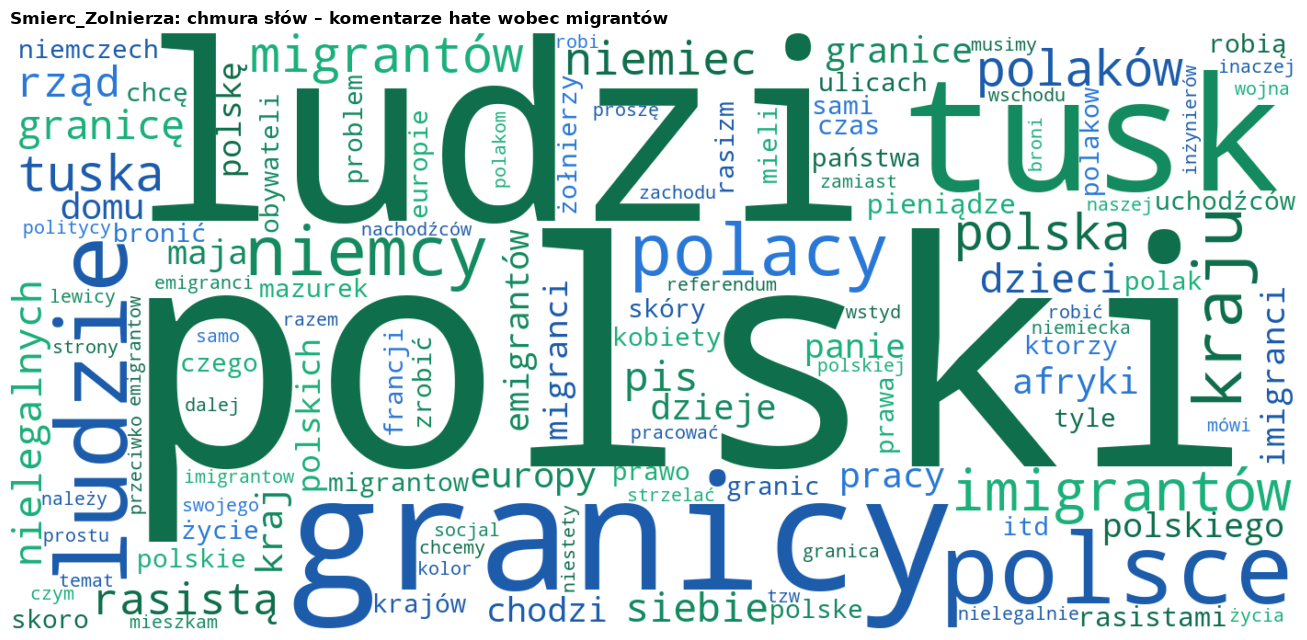

In [10]:
GREENS = ["#0f6e4c", "#138a5f", "#1baf7a", "#2a78d6", "#1c5cab"]


def wc_color(word, font_size, position, orientation, random_state=None, **kw):
    return random_state.choice(GREENS)


wc = WordCloud(width=1400, height=650, background_color="white", max_words=120, color_func=wc_color,
               random_state=SEED, prefer_horizontal=0.9).generate_from_frequencies(word_counts)
fig, ax = plt.subplots(figsize=(14, 6.5))
ax.imshow(wc, interpolation="bilinear")
ax.axis("off")
ax.set_title(f"{EVENT}: chmura słów – komentarze hate wobec migrantów")
plt.tight_layout()
plt.show()

In [11]:
# te same top słowa osobno przed i po - co się zmieniło w słownictwie
side = pd.concat({okres: pd.DataFrame(top_words(hm.loc[hm["okres"] == okres, "text"]).most_common(TOP_N_WORDS),
                                      columns=["słowo", "liczba"]) for okres in ["przed", "po"]}, axis=1)
side

przed                 po       
            słowo liczba       słowo liczba
0       emigranci    2.0      polski    321
1       republika    1.0       ludzi    186
2          prawdy    1.0     granicy    180
3           unika    1.0        tusk    180
4           super    1.0      polsce    179
5     manipulacja    1.0      ludzie    174
6       białorusi    1.0      polacy    162
7          świata    1.0      niemcy    145
8        białoruś    1.0       kraju    140
9         robicie    1.0  imigrantów    139
10        wrogami    1.0   migrantów    135
11  bialorusinami    1.0     polaków    132
12         gorzej    1.0      polska    132
13         komuny    1.0       tuska    130
14            NaN    NaN     niemiec    112
15            NaN    NaN     rasistą    101
16            NaN    NaN        rząd     91
17            NaN    NaN         pis     87
18            NaN    NaN     granicę     85
19            NaN    NaN      dzieci     84

## 5. Testy statystyczne: przed vs po

Dla każdej etykiety (`hate`, `hate_migrant`, `migrant` + dodatkowo `hate_migrant` wśród komentarzy o migracji):

1. **Test χ² (tabela 2×2)** okres × etykieta – czy odsetek różni się między okresami; różnica odsetków z 95% CI (Newcombe),
   iloraz ryzyka (RR) i wielkość efektu **Cohen's h** (0.2 mały, 0.5 średni, 0.8 duży).
2. **Regresja logistyczna z błędami klastrowanymi po wątku** – komentarze w jednym wątku nie są niezależne
   (jedna dyskusja potrafi „nakręcić” hejt), więc χ² zawyża istotność. To bardziej konserwatywny test tej samej hipotezy.
3. **Mann–Whitney U na dziennych odsetkach** – jednostką jest dzień (tylko dni z ≥ `MIN_DAILY_N` komentarzami).

p-value korygowane metodą Holma w obrębie każdego testu. Istotność (`ALPHA` = 0.05) sprawdzana jest **osobno dla każdego
testu** (kolumny `istotne χ²`, `istotne logit klaster`, `istotne Mann-Whitney`), `zgodność` = ile z 3 testów wskazuje zmianę.

**Wniosek główny:** zmiana jest istotna, jeśli wychodzi w **obu ostrożnych testach** – logit klastrowanym (wątki)
**i** Mann–Whitney (dni). χ² pokazany do porównania – przy tylu komentarzach prawie zawsze wychodzi istotny.

In [12]:
ALPHA = 0.05
groups = pd.factorize(df["thread_id"])[0]
TESTS = {"hate": df, "hate_migrant": df, "migrant": df, "hate_migrant | migrant": df[df["migrant"]]}

rows = []
for name, d in TESTS.items():
    lab = name.split(" |")[0]
    pre, post = d[d["okres"] == "przed"][lab], d[d["okres"] == "po"][lab]
    k1, n1, k2, n2 = pre.sum(), len(pre), post.sum(), len(post)
    p1, p2 = k1 / n1, k2 / n2
    chi2, p_chi, _, _ = stats.chi2_contingency([[k1, n1 - k1], [k2, n2 - k2]])
    lo, hi = confint_proportions_2indep(k2, n2, k1, n1, method="newcomb")
    h = 2 * np.arcsin(np.sqrt(p2)) - 2 * np.arcsin(np.sqrt(p1))

    m = smf.logit(f"y ~ po", data=d.assign(y=d[lab].astype(int))).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread_id"])[0]})

    dd = d.groupby("relative_day").agg(n=(lab, "size"), k=(lab, "sum"))
    dd = dd[dd["n"] >= MIN_DAILY_N].assign(p=lambda x: x["k"] / x["n"])
    mw = stats.mannwhitneyu(dd.loc[dd.index < POST_FROM_DAY, "p"], dd.loc[dd.index >= POST_FROM_DAY, "p"])

    rows.append({"etykieta": name, "przed %": 100 * p1, "po %": 100 * p2, "różnica pp": 100 * (p2 - p1),
                 "95% CI pp": f"[{100 * lo:.2f}, {100 * hi:.2f}]", "RR": p2 / p1 if p1 else np.nan,
                 "Cohen h": h, "χ²": chi2, "p χ²": p_chi,
                 "OR (logit, klaster)": np.exp(m.params["po"]), "p logit klaster": m.pvalues["po"],
                 "p Mann-Whitney (dni)": mw.pvalue})

tests = pd.DataFrame(rows).set_index("etykieta")
P_COLS = {"χ²": "p χ²", "logit klaster": "p logit klaster", "Mann-Whitney": "p Mann-Whitney (dni)"}
for test, col in P_COLS.items():
    tests[col + " (Holm)"] = multipletests(tests[col], method="holm")[1]
    tests[f"istotne {test}"] = tests[col + " (Holm)"] < ALPHA
# ile z 3 testów wskazuje istotną zmianę (po korekcie Holma)
tests["zgodność"] = tests[[f"istotne {t}" for t in P_COLS]].sum(axis=1).astype(str) + "/3"
# wniosek główny: oba ostrożne testy (wątki i dni) muszą się zgadzać; χ² tylko do porównania
tests["istotne (logit klaster i Mann-Whitney)"] = tests["istotne logit klaster"] & tests["istotne Mann-Whitney"]

display(fmt_p(tests, 3))
display(tests[[f"istotne {t}" for t in P_COLS] + ["zgodność", "istotne (logit klaster i Mann-Whitney)"]]
        .replace({True: "✅", False: "❌"}))

C:\Users\julia\AppData\Local\Temp\ipykernel_44780\1127101350.py:20: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  mw = stats.mannwhitneyu(dd.loc[dd.index < POST_FROM_DAY, "p"], dd.loc[dd.index >= POST_FROM_DAY, "p"])


,przed %,po %,różnica pp,95% CI pp,RR,Cohen h,χ²,p χ²,"OR (logit, klaster)",p logit klaster,p Mann-Whitney (dni),p χ² (Holm),istotne χ²,p logit klaster (Holm),istotne logit klaster,p Mann-Whitney (dni) (Holm),istotne Mann-Whitney,zgodność,istotne (logit klaster i Mann-Whitney)
etykieta,,,,,,,,,,,,,,,,,,,
hate,1.010,7.535,6.524,"[2.03, 7.40]",7.459,0.355,5.144,0.0233,7.985,1.53e-13,0.427,0.07,False,6.1e-13,True,1,False,1/3,False
hate_migrant,1.010,5.595,4.584,"[0.09, 5.45]",5.539,0.276,3.115,0.0776,5.808,4.61e-12,0.634,0.155,False,1.38e-11,True,1,False,1/3,False
migrant,3.030,12.716,9.685,"[4.17, 11.71]",4.196,0.379,7.508,0.00614,4.662,1.93e-05,0.333,0.0246,True,3.86e-05,True,1,False,2/3,False
hate_migrant | migrant,33.333,43.997,10.664,"[-35.26, 37.88]",1.320,0.219,0.000,1,1.571,0.00744,nan,1,False,0.00744,True,nan,False,1/3,False


,istotne χ²,istotne logit klaster,istotne Mann-Whitney,zgodność,istotne (logit klaster i Mann-Whitney)
etykieta,,,,,
hate,❌,✅,❌,1/3,❌
hate_migrant,❌,✅,❌,1/3,❌
migrant,✅,✅,❌,2/3,❌
hate_migrant | migrant,❌,✅,❌,1/3,❌


In [13]:
for name, r in tests.iterrows():
    kier = "wzrost" if r["różnica pp"] > 0 else "spadek"
    sig = "ISTOTNA" if r["istotne (logit klaster i Mann-Whitney)"] else "nieistotna"
    marks = ", ".join(f"{t} {'✅' if r[f'istotne {t}'] else '❌'}" for t in P_COLS)
    print(f"{name:24s}: {r['przed %']:.2f}% -> {r['po %']:.2f}% ({kier} o {abs(r['różnica pp']):.2f} pp, "
          f"RR={r['RR']:.2f}, h={r['Cohen h']:.3f}) - różnica {sig} "
          f"[{marks}; zgodność {r['zgodność']}]")

hate                    : 1.01% -> 7.53% (wzrost o 6.52 pp, RR=7.46, h=0.355) - różnica nieistotna [χ² ❌, logit klaster ✅, Mann-Whitney ❌; zgodność 1/3]
hate_migrant            : 1.01% -> 5.59% (wzrost o 4.58 pp, RR=5.54, h=0.276) - różnica nieistotna [χ² ❌, logit klaster ✅, Mann-Whitney ❌; zgodność 1/3]
migrant                 : 3.03% -> 12.72% (wzrost o 9.69 pp, RR=4.20, h=0.379) - różnica nieistotna [χ² ✅, logit klaster ✅, Mann-Whitney ❌; zgodność 2/3]
hate_migrant | migrant  : 33.33% -> 44.00% (wzrost o 10.66 pp, RR=1.32, h=0.219) - różnica nieistotna [χ² ❌, logit klaster ✅, Mann-Whitney ❌; zgodność 1/3]


## 6. Kogo obrażano? Komentarze `hate_migrant` po wydarzeniu wg grup (słowa kluczowe)

Grupy wykrywane wyrażeniami regularnymi (z polskimi znakami i bez). Komentarz może trafić do kilku grup, dlatego
pokazane są dwa widoki: **wielo-etykietowy** (sumy > 100%) i **rozłączny** (jedna grupa / kilka grup / brak słowa kluczowego).
Listę `TARGET_GROUPS` łatwo rozszerzyć. „Brak słowa kluczowego” = hejt wobec migrantów bez nazwania grupy
(np. „oni”, „ci ludzie”) – warto przejrzeć przykłady.

In [14]:
TARGET_GROUPS = {
    "Ukraińcy": r"ukrai|ukraiń|\bukr|ukrop|bander|\bupa\b|upain|upowc|slava|sława|chachoł|chochoł",
    "Muzułmanie / Arabowie / Bliski Wschód": r"muzu?ł?m|muslim|islam|arab|allah|ciap|kozoj|talib|afga|syryj|syri|irak|turk|turc|pakist|czeczen|kebab|szariat|meczet",
    "Afrykanie / czarnoskórzy": r"murzyn|afryk|czarn|bambus|asfalt|nigeri|somal|erytre|małp|malp",
    "Migranci / uchodźcy (ogólnie)": r"migran|imigran|uchodź|uchodz|nachodź|nachodz|najeźdź|najezdz|relokac|azyl|ubogac|nielegal|przybysz|inwazj",
}
GROUP_RE = {g: re.compile(p) for g, p in TARGET_GROUPS.items()}
GROUP_COLORS = dict(zip(TARGET_GROUPS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))

hm = df[df["hate_migrant"]].copy()
for g, rx in GROUP_RE.items():
    hm[g] = hm["text"].str.lower().apply(lambda t: bool(rx.search(t)))
n_groups = hm[list(TARGET_GROUPS)].sum(axis=1)
hm["grupa"] = np.select(
    [n_groups == 0, n_groups > 1],
    ["brak słowa kluczowego", "kilka grup"],
    default=hm[list(TARGET_GROUPS)].idxmax(axis=1),
)
hm_po = hm[hm["okres"] == "po"]

multi = pd.DataFrame({okres: 100 * hm.loc[hm["okres"] == okres, list(TARGET_GROUPS)].mean()
                      for okres in ["przed", "po"]})
multi["po [n]"] = hm_po[list(TARGET_GROUPS)].sum()
excl = pd.concat({okres: hm.loc[hm["okres"] == okres, "grupa"].value_counts() for okres in ["przed", "po"]},
                 axis=1).fillna(0).astype(int)
excl_pct = 100 * excl / excl.sum()

print(f"hate_migrant po wydarzeniu: {len(hm_po)} komentarzy")
print("\nwidok wielo-etykietowy (% komentarzy hate_migrant zawierających grupę):")
display(multi.round(2))
print("rozłączny (n i %):")
display(pd.concat([excl, excl_pct.round(2).add_suffix(" %")], axis=1))

hate_migrant po wydarzeniu: 2111 komentarzy

widok wielo-etykietowy (% komentarzy hate_migrant zawierających grupę):


,przed,po,po [n]
Ukraińcy,0.0,9.14,193
Muzułmanie / Arabowie / Bliski Wschód,0.0,8.86,187
Afrykanie / czarnoskórzy,0.0,9.10,192
Migranci / uchodźcy (ogólnie),100.0,41.88,884


rozłączny (n i %):


,przed,po,przed %,po %
grupa,,,,
Migranci / uchodźcy (ogólnie),1,729,100.0,34.53
brak słowa kluczowego,0,897,0.0,42.49
kilka grup,0,196,0.0,9.28
Ukraińcy,0,116,0.0,5.50
Muzułmanie / Arabowie / Bliski Wschód,0,91,0.0,4.31
Afrykanie / czarnoskórzy,0,82,0.0,3.88


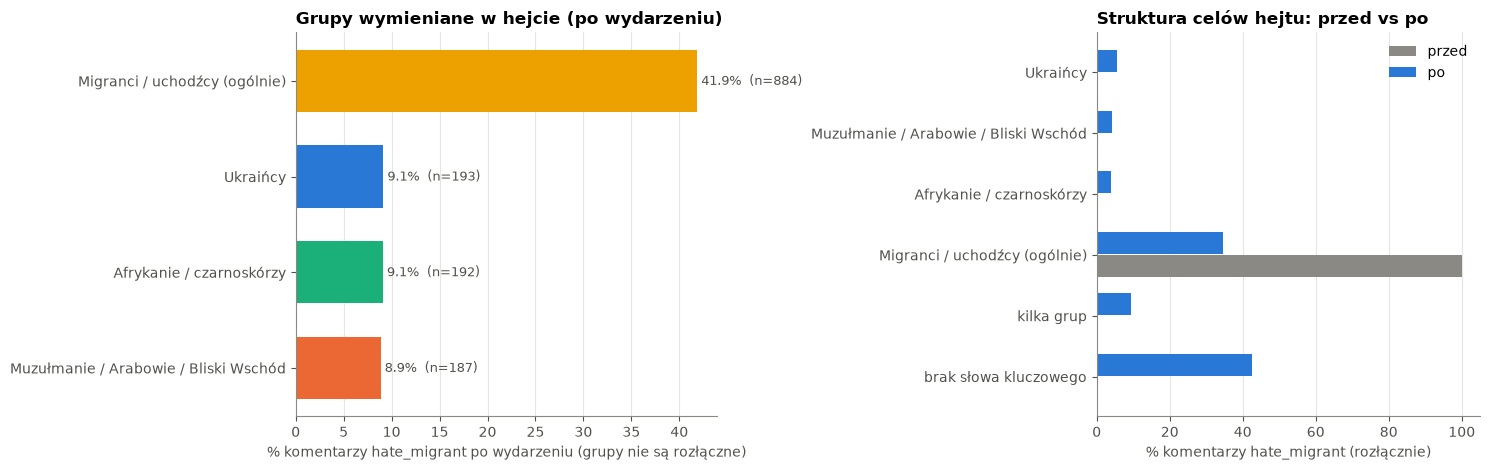

χ² struktura grup przed vs po: χ²=1.89, df=5, p=0.864


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})

ax = axes[0]
s = multi["po"].sort_values()
ax.barh(s.index, s.values, color=[GROUP_COLORS[g] for g in s.index], height=0.65)
for y, (g, v) in enumerate(s.items()):
    ax.text(v, y, f" {v:.1f}%  (n={multi.loc[g, 'po [n]']})", va="center", color=INK2, fontsize=9)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("% komentarzy hate_migrant po wydarzeniu (grupy nie są rozłączne)")
ax.set_title("Grupy wymieniane w hejcie (po wydarzeniu)")

ax = axes[1]
order = [*TARGET_GROUPS, "kilka grup", "brak słowa kluczowego"]
e = excl_pct.reindex(order).fillna(0)
y = np.arange(len(order))
for i, okres in enumerate(["przed", "po"]):
    ax.barh(y + (0.5 - i) * 0.38, e[okres], 0.36, color=COLORS[okres], label=okres)
ax.set_yticks(y, order)
ax.invert_yaxis()
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("% komentarzy hate_migrant (rozłącznie)")
ax.set_title("Struktura celów hejtu: przed vs po")
ax.legend()
plt.tight_layout()
plt.show()

# czy struktura celów zmieniła się po wydarzeniu?
chi2, p, dof, _ = stats.chi2_contingency(excl.loc[excl.sum(axis=1) > 0])
print(f"χ² struktura grup przed vs po: χ²={chi2:.2f}, df={dof}, p={p:.3g}")

In [16]:
# przykłady (losowe) do weryfikacji, czy słowa kluczowe dobrze przypisują grupy
for g in order:
    sample = hm_po[hm_po["grupa"] == g]
    print(f"\n=== {g} (n={len(sample)}) ===")
    for t in sample["text"].sample(min(4, len(sample)), random_state=SEED):
        print(" -", t[:220].replace("\n", " "))


=== Ukraińcy (n=116) ===
 - Wszyscy jesteśmy nazywani RASISTAMI przez walniętych pseudo-dziennikarzy i pseudo-polityków, którzy, jak za dotknięciem czarodziejskiej różdżki, zaczęli Polaków wyzywać od rasistów! Czy to przypadek, czy po prostu dostal
 - To wy pisopeofcy jesteście winni śmierci tego młodego żołnierza wysyłając go bez kamizelki kóloodpornej i obstawy .Cały sejm i rząd na ukraine walczyć a nie wciągać nas zdrajcy
 - Rachoń cieciu opowiedz ile wydaliscmy na socjale dla ukrainców, na przywileje, na broń ile miardów zlotych posżło na tych niewdziczników?
 - Polityka PiS.  Polacy A ukraincami bo jest wojna...pis przukljmujemy, dajemy zasiłki. Polacy wkorzeni na Ukraińców. Pis przeciwko Ukraińcom. Populizm...

=== Muzułmanie / Arabowie / Bliski Wschód (n=91) ===
 - Wybraliscie taki rzad to macie Polska jest juz wojewodztwem europy a tust jest wojewoda robi to co niemcy chca ... CpK nie i wszystkie strategiczne inwestycje stoją .... teraz ciapatych bedzie mnogo 😂😂😂 ale jest fajn

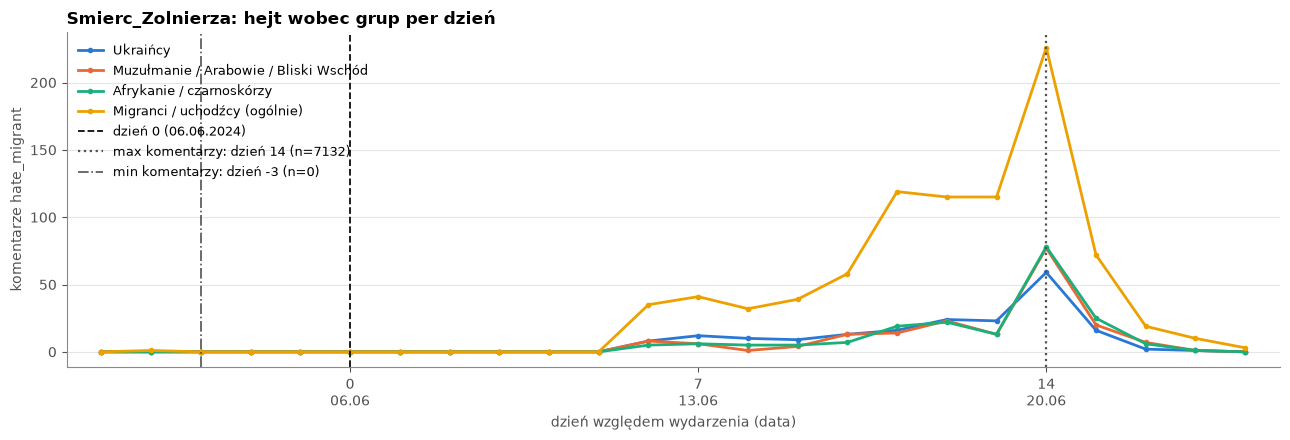

In [17]:
# dzienny przebieg hejtu wobec poszczególnych grup (wielo-etykietowo)
daily_groups = hm.groupby("relative_day")[list(TARGET_GROUPS)].sum().reindex(days, fill_value=0)
fig, ax = plt.subplots()
for g in TARGET_GROUPS:
    ax.plot(daily_groups.index, daily_groups[g], marker="o", ms=3, color=GROUP_COLORS[g], label=g)
mark_days(ax)
ax.set_ylabel("komentarze hate_migrant")
ax.set_title(f"{EVENT}: hejt wobec grup per dzień")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

## 7. Dodatkowe analizy (propozycje)

### 7.1 Przerwany szereg czasowy (interrupted time series)

Test przed/po porównuje tylko średnie. Model segmentowy rozdziela **skok poziomu** w dniu 0 (`po`) od
**zmiany trendu** (`relative_day:po`) – odróżnia „jednorazowy wybuch” od trwałego wzrostu. Regresja logistyczna na
poziomie komentarza, błędy klastrowane po wątku; współczynniki jako ilorazy szans (OR).

c:\Users\julia\Documents\pgm\Social_Media_Hate_Speech\venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\julia\Documents\pgm\Social_Media_Hate_Speech\venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


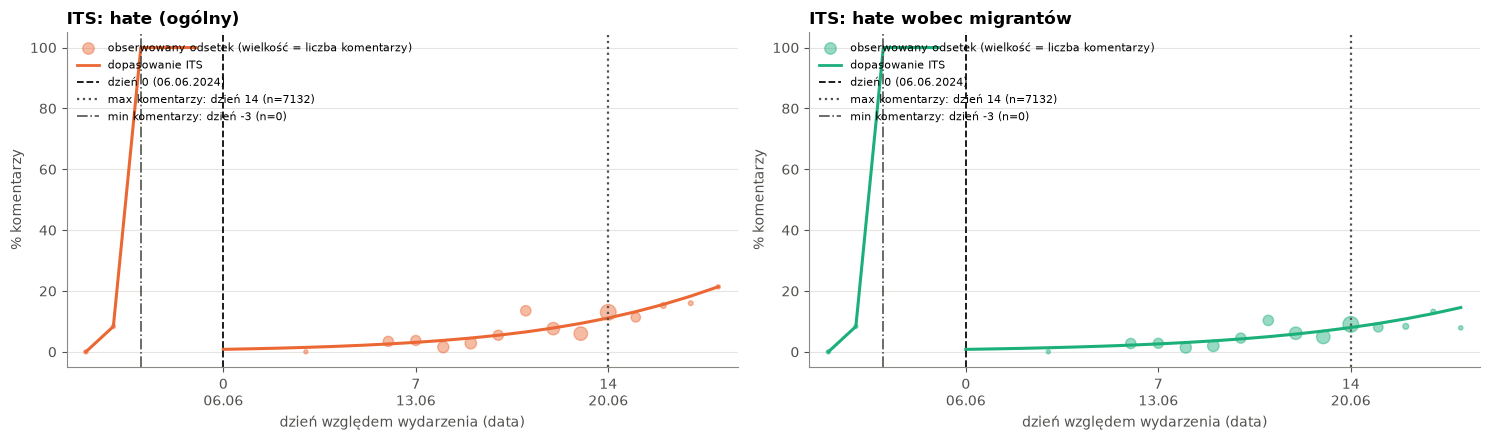

OR                      95% CI  p
etykieta     człon                                                      
hate         po                     0.000              [0.000, 0.000]  0
             relative_day     1310265.449  [1310263.561, 1310267.338]  0
             relative_day:po        0.000              [0.000, 0.000]  0
hate_migrant po                     0.000              [0.000, 0.000]  0
             relative_day     1310265.333  [1310265.084, 1310265.583]  0
             relative_day:po        0.000              [0.000, 0.000]  0

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=False)
its_rows = []
for ax, lab in zip(axes, ["hate", "hate_migrant"]):
    m = smf.logit("y ~ relative_day + po + relative_day:po", data=df.assign(y=df[lab].astype(int))).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": groups})
    for term in ["po", "relative_day", "relative_day:po"]:
        its_rows.append({"etykieta": lab, "człon": term, "OR": np.exp(m.params[term]),
                         "95% CI": f"[{np.exp(m.conf_int().loc[term, 0]):.3f}, {np.exp(m.conf_int().loc[term, 1]):.3f}]",
                         "p": m.pvalues[term]})
    pred = m.predict(pd.DataFrame({"relative_day": daily.index, "po": (daily.index >= POST_FROM_DAY).astype(int)}))
    ok = daily["komentarze"] >= MIN_DAILY_N
    ax.scatter(daily.index[ok], daily.loc[ok, f"{lab}_%"], s=8 + daily.loc[ok, "komentarze"] / daily["komentarze"].max() * 120,
               color=COLORS[lab], alpha=0.45, label="obserwowany odsetek (wielkość = liczba komentarzy)")
    for seg in (daily.index < POST_FROM_DAY, daily.index >= POST_FROM_DAY):
        ax.plot(daily.index[seg], 100 * pred[seg], color=COLORS[lab], lw=2.2)
    ax.plot([], [], color=COLORS[lab], label="dopasowanie ITS")
    mark_days(ax)
    ax.set_ylabel("% komentarzy")
    ax.set_title(f"ITS: {LABEL_NAMES[lab]}")
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()
display(fmt_p(pd.DataFrame(its_rows).set_index(["etykieta", "człon"]), 3))

### 7.3 Zaangażowanie: czy hejt dostaje więcej polubień?

Mann–Whitney U na liczbie lajków, osobno w każdym okresie.

In [19]:
rows = []
for okres in ["przed", "po", "ogółem"]:
    d = df if okres == "ogółem" else df[df["okres"] == okres]
    for lab in ["hate", "hate_migrant"]:
        a, b = d.loc[d[lab], "likes"].dropna(), d.loc[~d[lab], "likes"].dropna()
        mw = stats.mannwhitneyu(a, b)
        rows.append({"okres": okres, "etykieta": lab, f"mediana lajków (z etykietą)": a.median(),
                     "mediana lajków (reszta)": b.median(), "średnia (z etykietą)": a.mean(),
                     "średnia (reszta)": b.mean(), "p Mann-Whitney": mw.pvalue})
display(fmt_p(pd.DataFrame(rows).set_index(["okres", "etykieta"]), 2))

mediana lajków (z etykietą)  mediana lajków (reszta)  \
okres  etykieta                                                             
przed  hate                                  0.0                      1.5   
       hate_migrant                          0.0                      1.5   
po     hate                                  0.0                      1.0   
       hate_migrant                          0.0                      1.0   
ogółem hate                                  0.0                      1.0   
       hate_migrant                          0.0                      1.0   

                     średnia (z etykietą)  średnia (reszta) p Mann-Whitney  
okres  etykieta                                                             
przed  hate                          0.00              9.10          0.322  
       hate_migrant                  0.00              9.10          0.322  
po     hate                         13.18             12.61       3.61e-18  
       hate_migrant                 13.92             12.58       1.97e-17  
ogółem hate                         13.18             12.60       2.43e-18  
       hate_migrant                 13.91             12.57       1.36e-17

### 7.4 Gdzie powstaje hejt: wątki i głębokość dyskusji

Top materiały (wątki) z największą liczbą komentarzy hate_migrant po wydarzeniu oraz odsetek hejtu wg poziomu odpowiedzi (`depth`).

In [20]:
thr = (df[df["okres"] == "po"].groupby("thread_id")
       .agg(komentarze=("comment_id", "size"), hate_migrant=("hate_migrant", "sum")))
thr["hate_migrant %"] = 100 * thr["hate_migrant"] / thr["komentarze"]
top_thr = thr.sort_values("hate_migrant", ascending=False).head(10)
print(f"top 10 wątków (z {len(thr)}) zawiera {top_thr['hate_migrant'].sum() / thr['hate_migrant'].sum():.1%} hejtu wobec migrantów po wydarzeniu")
display(top_thr.round(1))

depth = df.groupby(["depth", "okres"])[["hate", "hate_migrant"]].mean().mul(100).unstack("okres").round(2)
depth["n"] = df.groupby("depth").size()
depth

top 10 wątków (z 229) zawiera 62.7% hejtu wobec migrantów po wydarzeniu


,komentarze,hate_migrant,hate_migrant %
thread_id,,,
P00061,3096,604,19.5
P00227,322,124,38.5
P00089,626,110,17.6
P00058,3319,99,3.0
P00199,165,77,46.7
P00223,205,68,33.2
P00196,700,66,9.4
P00180,157,62,39.5
P00025,273,59,21.6


hate       hate_migrant            n
okres    po przed           po przed       
depth                                      
1      7.53  1.01         5.59  1.01  37832

### 7.5 Kategorie obelg (słownik regex) wśród hate_migrant – przed vs po

Z pliku `slurs/comments.csv` (jeśli istnieje dla tej platformy): które typy obelg (etniczne, dehumanizacja, kod inwazji...) rosną po wydarzeniu.

In [21]:
slur_file = EVENT_DIR / "slurs" / "comments.csv"
if slur_file.exists():
    slurs = pd.read_csv(slur_file, encoding="utf-8-sig", dtype={"comment_id": str},
                        usecols=["comment_id", "slur_categories"]).drop_duplicates("comment_id")
    sc = (df[["comment_id", "okres"]].merge(slurs, on="comment_id").dropna(subset=["slur_categories"])
          .assign(kat=lambda x: x["slur_categories"].str.split(r";\s*")).explode("kat"))
    n_okres = df["okres"].value_counts()
    cat = sc.groupby(["kat", "okres"]).size().unstack(fill_value=0).reindex(columns=["przed", "po"], fill_value=0)
    cat_rate = (cat / n_okres[cat.columns] * 1000).round(2).add_suffix(" / 1000 kom.")
    cat_rate["zmiana ×"] = (cat_rate["po / 1000 kom."] / cat_rate["przed / 1000 kom."].replace(0, np.nan)).round(2)
    display(pd.concat([cat, cat_rate], axis=1).sort_values("po", ascending=False))
else:
    print("brak pliku slurs/ dla tego wydarzenia")

okres,przed,po,przed / 1000 kom.,po / 1000 kom.,zmiana ×
kat,,,,,
obelga,0,296,0.0,7.84,NaN
dehumanizacja,1,196,10.1,5.19,0.51
kod_inwazji,0,56,0.0,1.48,NaN
kod_ironiczny,0,46,0.0,1.22,NaN
kod_historyczny,0,41,0.0,1.09,NaN
obelga_etniczna,0,27,0.0,0.72,NaN
kod,0,25,0.0,0.66,NaN
kod_spiskowy,0,21,0.0,0.56,NaN
stereotyp,0,14,0.0,0.37,NaN
